In [1]:
# Comprobar las tablas necesarias
tablas = ["fact_aire", "fact_trafico", "dim_tiempo",
          "dim_estacion", "dim_espira", "dim_contaminante"]

for tabla in tablas:
    df = spark.table(tabla)
    print(f"\nTABLA: {tabla}")
    print(f"Registros: {df.count()}")
    df.printSchema()
    display(df.limit(5))

StatementMeta(, 9504b602-a31d-41d8-b1fa-53229e437b8d, 3, Finished, Available, Finished, False)


TABLA: fact_aire
Registros: 2215570
root
 |-- id_tiempo: integer (nullable = false)
 |-- id_estacion: string (nullable = false)
 |-- id_contaminante: integer (nullable = false)
 |-- id_distrito: integer (nullable = true)
 |-- concentracion: double (nullable = true)



SynapseWidget(Synapse.DataFrame, 7a878fea-c61c-484c-9ae3-719de844fd43)


TABLA: fact_trafico
Registros: 11637477
root
 |-- id_tiempo: integer (nullable = false)
 |-- id_espira: string (nullable = false)
 |-- id_distrito: integer (nullable = false)
 |-- intensidad: double (nullable = true)



SynapseWidget(Synapse.DataFrame, a31a0926-d32b-42d0-9499-f160fe6e58cb)


TABLA: dim_tiempo
Registros: 131472
root
 |-- id_tiempo: integer (nullable = false)
 |-- fecha_hora: timestamp (nullable = false)
 |-- fecha: date (nullable = false)
 |-- anio: integer (nullable = true)
 |-- mes: integer (nullable = true)
 |-- dia: integer (nullable = true)
 |-- hora: integer (nullable = true)
 |-- es_fin_de_semana: boolean (nullable = true)
 |-- es_festivo: boolean (nullable = true)
 |-- nombre_festivo: string (nullable = true)
 |-- es_evento: boolean (nullable = true)
 |-- nombre_evento: string (nullable = true)
 |-- es_confinamiento: boolean (nullable = true)
 |-- dia_semana: integer (nullable = true)
 |-- nombre_dia: string (nullable = true)
 |-- nombre_mes: string (nullable = true)
 |-- trimestre: integer (nullable = true)



... (3 outputs left out)


TABLA: dim_espira
Registros: 964
root
 |-- id_espira: string (nullable = false)
 |-- latitud: double (nullable = true)
 |-- longitud: double (nullable = true)
 |-- id_distrito: integer (nullable = true)



SynapseWidget(Synapse.DataFrame, bfff2a61-ff95-4c33-9229-5923150f5bd9)


TABLA: dim_contaminante
Registros: 4
root
 |-- id_contaminante: integer (nullable = false)
 |-- nombre: string (nullable = true)
 |-- unidad: string (nullable = true)
 |-- indicador: string (nullable = true)
 |-- limite_ue_actual: double (nullable = true)
 |-- objetivo_ue_2030: double (nullable = true)
 |-- guia_oms_2021: double (nullable = true)



SynapseWidget(Synapse.DataFrame, cd7ad497-9b68-4f91-831e-4dec938e5f26)

In [2]:
from pyspark.sql import functions as F

# Cargar las tablas
aire = spark.table("fact_aire")
trafico = spark.table("fact_trafico")
tiempo = spark.table("dim_tiempo")

# Incorporar el año a cada dataset
aire_anios = aire.join(tiempo.select("id_tiempo", "anio"), "id_tiempo", "left")
trafico_anios = trafico.join(tiempo.select("id_tiempo", "anio"), "id_tiempo", "left")

# Comprobar registros por año
print("REGISTROS DE AIRE POR AÑO")
display(aire_anios.groupBy("anio").count().orderBy("anio"))

print("REGISTROS DE TRÁFICO POR AÑO")
display(trafico_anios.groupBy("anio").count().orderBy("anio"))

StatementMeta(, 9504b602-a31d-41d8-b1fa-53229e437b8d, 4, Finished, Available, Finished, False)

REGISTROS DE AIRE POR AÑO


SynapseWidget(Synapse.DataFrame, 8a5f3888-eac2-4347-8852-d149e9a0dbc4)

REGISTROS DE TRÁFICO POR AÑO


SynapseWidget(Synapse.DataFrame, eaba208e-e080-4f43-b41f-183841aeefa8)

In [3]:
# Seleccionar fechas de 2023 a 2025
fechas = (
    spark.table("dim_tiempo").select("id_tiempo", "fecha", "anio")
    .filter(F.col("anio").between(2023, 2025))
)

contaminantes = spark.table("dim_contaminante").select("id_contaminante", "nombre")

# Concentración media diaria por distrito
aire_diario = (
    spark.table("fact_aire")
    .join(fechas, "id_tiempo", "inner")
    .join(contaminantes, "id_contaminante", "inner")
    .filter(F.col("nombre").isin("NO2", "PM10", "PM2.5") & F.col("id_distrito").isNotNull())
    .groupBy("fecha", "id_distrito", "nombre")
    .agg(
        F.avg("concentracion").alias("concentracion_media"),
        F.countDistinct("id_estacion").alias("n_estaciones")
    )
)

# Intensidad media diaria por sensor
trafico_sensor_diario = (
    spark.table("fact_trafico")
    .join(fechas, "id_tiempo", "inner")
    .filter(F.col("id_distrito").isNotNull() & F.col("intensidad").isNotNull())
    .groupBy("fecha", "id_distrito", "id_espira")
    .agg(F.avg("intensidad").alias("intensidad_sensor"))
)

# Intensidad media diaria por distrito
trafico_diario = (
    trafico_sensor_diario.groupBy("fecha", "id_distrito")
    .agg(
        F.avg("intensidad_sensor").alias("intensidad_media"),
        F.countDistinct("id_espira").alias("n_espiras")
    )
)

# Integrar aire y tráfico por fecha y distrito
datos_integrados = (
    aire_diario.join(trafico_diario, ["fecha", "id_distrito"], "inner")
    .orderBy("fecha", "id_distrito", "nombre")
)

print("Registros integrados:", datos_integrados.count())
display(datos_integrados.limit(20))

StatementMeta(, 9504b602-a31d-41d8-b1fa-53229e437b8d, 5, Finished, Available, Finished, False)

Registros integrados: 8086


SynapseWidget(Synapse.DataFrame, 5d9766a6-53fd-4f9b-9b3f-1c6b9a392d24)

In [4]:
# Comprobar la disponibilidad y calidad de los datos integrados
resumen_integracion = (
    datos_integrados.withColumn("anio", F.year("fecha"))
    .groupBy("anio", "nombre")
    .agg(
        F.count("*").alias("observaciones"),
        F.countDistinct("fecha").alias("dias"),
        F.countDistinct("id_distrito").alias("distritos"),
        F.min("n_espiras").alias("min_espiras"),
        F.max("n_espiras").alias("max_espiras"),
        F.min("n_estaciones").alias("min_estaciones"),
        F.max("n_estaciones").alias("max_estaciones"),
        F.sum(F.when(
            F.col("concentracion_media").isNull() | F.col("intensidad_media").isNull(), 1
        ).otherwise(0)).alias("registros_nulos")
    )
    .orderBy("anio", "nombre")
)

display(resumen_integracion)
print("Total de observaciones integradas:", datos_integrados.count())

StatementMeta(, 9504b602-a31d-41d8-b1fa-53229e437b8d, 6, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, 58de9a46-cd7a-44db-afea-6caa9d589697)

Total de observaciones integradas: 8086


In [5]:
from pyspark.sql.window import Window

# Seleccionar observaciones válidas
df = datos_integrados.dropna(subset=["concentracion_media", "intensidad_media"])

# Función para calcular Pearson y Spearman
def calcular_correlaciones(datos, grupos):

    # Correlación de Pearson
    pearson = datos.groupBy(*grupos).agg(
        F.count("*").alias("observaciones"),
        F.corr("intensidad_media", "concentracion_media").alias("pearson")
    )

    # Rangos medios para Spearman (incluyendo empates)
    w_trafico = Window.partitionBy(*grupos).orderBy("intensidad_media")
    w_aire = Window.partitionBy(*grupos).orderBy("concentracion_media")

    rangos = (
        datos
        .withColumn("rango_trafico", F.rank().over(w_trafico) +
                    (F.count("*").over(Window.partitionBy(*grupos, "intensidad_media")) - 1) / 2)
        .withColumn("rango_aire", F.rank().over(w_aire) +
                    (F.count("*").over(Window.partitionBy(*grupos, "concentracion_media")) - 1) / 2)
    )

    spearman = rangos.groupBy(*grupos).agg(
        F.corr("rango_trafico", "rango_aire").alias("spearman")
    )

    return (
        pearson.join(spearman, grupos)
        .withColumn("pearson", F.round("pearson", 3))
        .withColumn("spearman", F.round("spearman", 3))
    )

# Correlación global por contaminante
correlacion_global = calcular_correlaciones(df, ["nombre"])
print("CORRELACIÓN GLOBAL")
display(correlacion_global.orderBy("nombre"))

# Correlación por distrito y contaminante
correlacion_distrito = calcular_correlaciones(df, ["id_distrito", "nombre"])
print("CORRELACIÓN POR DISTRITO")
display(correlacion_distrito.orderBy("id_distrito", "nombre"))

StatementMeta(, 9504b602-a31d-41d8-b1fa-53229e437b8d, 7, Finished, Available, Finished, False)

CORRELACIÓN GLOBAL


SynapseWidget(Synapse.DataFrame, 9f7e0450-9871-4239-a688-d5d358a26a67)

CORRELACIÓN POR DISTRITO


SynapseWidget(Synapse.DataFrame, f29ce1a4-c816-456f-8587-6e8b4a67e669)

StatementMeta(, 9504b602-a31d-41d8-b1fa-53229e437b8d, 11, Finished, Available, Finished, False)

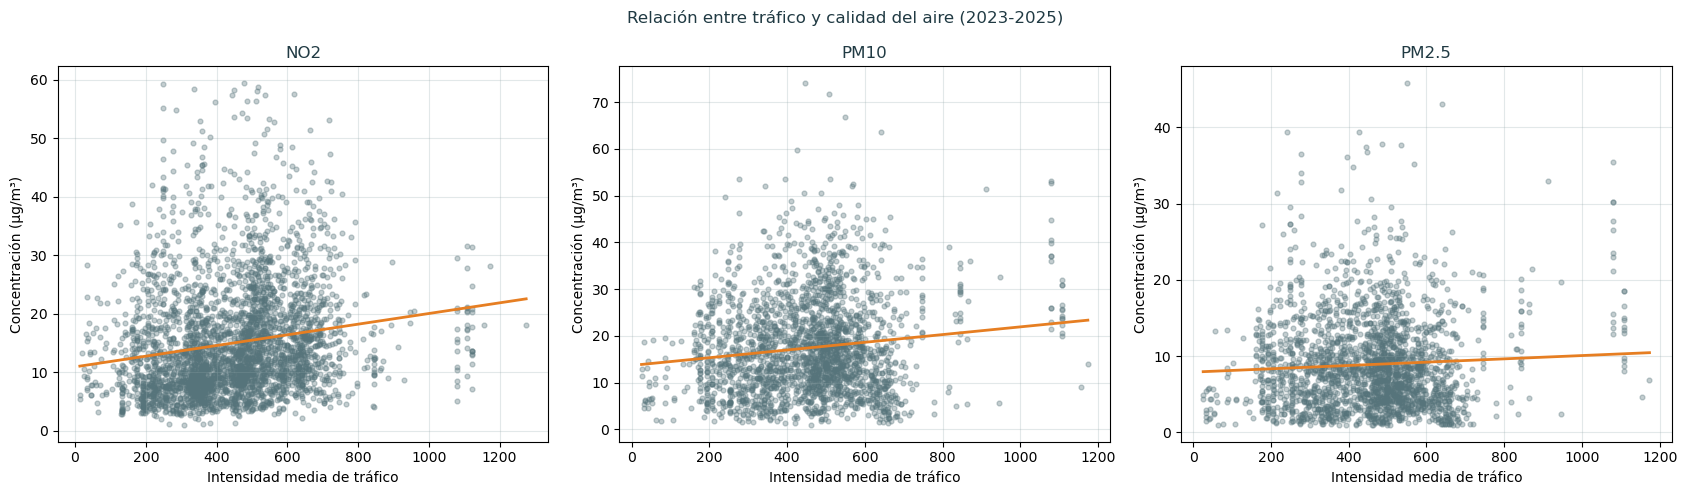

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import os

# Carpeta de salida
ruta = "/lakehouse/default/Files/export_graficos"
os.makedirs(ruta, exist_ok=True)

# Convertir a Pandas
pdf = datos_integrados.select(
    "nombre", "intensidad_media", "concentracion_media"
).dropna().toPandas()

# Crear tres gráficos
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, cont in zip(axes, ["NO2", "PM10", "PM2.5"]):
    datos = pdf[pdf["nombre"] == cont]
    x = datos["intensidad_media"].to_numpy()
    y = datos["concentracion_media"].to_numpy()

    # Puntos de dispersión
    ax.scatter(x, y, color="#56747B", alpha=0.35, s=12)

    # Línea de regresión
    if len(x) > 1 and np.std(x) > 0:
        pendiente, intercepto = np.polyfit(x, y, 1)
        x_linea = np.linspace(x.min(), x.max(), 100)
        ax.plot(x_linea, pendiente * x_linea + intercepto,
                color="#E67E22", linewidth=2)

    ax.set_title(cont, color="#203A43")
    ax.set_xlabel("Intensidad media de tráfico")
    ax.set_ylabel("Concentración (µg/m³)")
    ax.grid(color="#8FA5A8", alpha=0.25)

fig.suptitle("Relación entre tráfico y calidad del aire (2023-2025)",
             color="#203A43")

plt.tight_layout()

# Guardar solo PNG
plt.savefig(f"{ruta}/05_dispersion_trafico_calidad_aire_2023_2025.png",
            dpi=300, bbox_inches="tight")

plt.show()

StatementMeta(, 9504b602-a31d-41d8-b1fa-53229e437b8d, 19, Finished, Available, Finished, False)

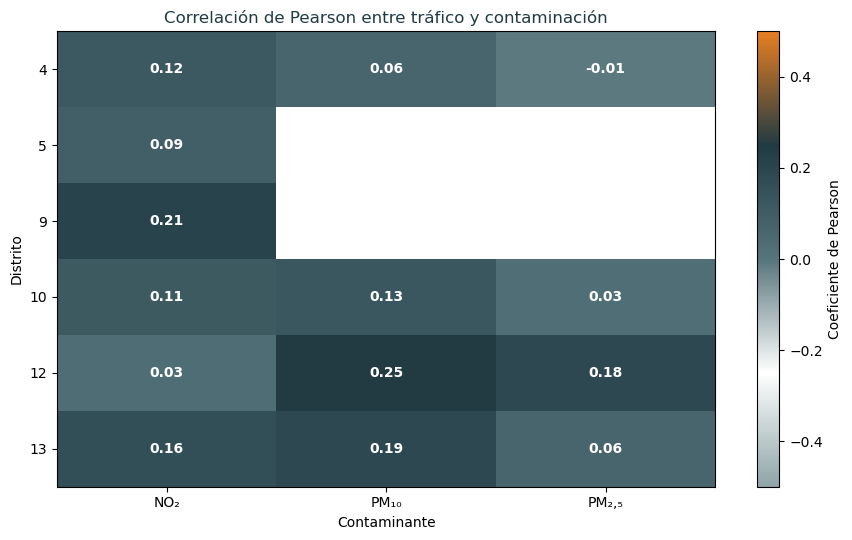

In [7]:
import matplotlib.pyplot as plt
import pandas as pd
import os
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

# Carpeta de salida
ruta = "/lakehouse/default/Files/export_graficos"
os.makedirs(ruta, exist_ok=True)

# Crear matriz de correlaciones
datos = correlacion_distrito.toPandas()
matriz = datos.pivot(index="id_distrito", columns="nombre", values="pearson")
matriz = matriz.reindex(columns=["NO2", "PM10", "PM2.5"]).sort_index()

# Paleta personalizada
colores = ["#8FA5A8", "#FFFFFF", "#56747B", "#203A43", "#E67E22"]
cmap = LinearSegmentedColormap.from_list("paleta_tfm", colores)
cmap.set_bad("white")

# Crear mapa de calor
fig, ax = plt.subplots(figsize=(9, 5.5))
imagen = ax.imshow(matriz.values, cmap=cmap,
                   norm=TwoSlopeNorm(vmin=-0.5, vcenter=0, vmax=0.5),
                   aspect="auto")

ax.set_xticks(range(3))
ax.set_xticklabels(["NO₂", "PM₁₀", "PM₂,₅"])
ax.set_yticks(range(len(matriz.index)))
ax.set_yticklabels(matriz.index)

ax.set_xlabel("Contaminante")
ax.set_ylabel("Distrito")
ax.set_title("Correlación de Pearson entre tráfico y contaminación",
             color="#203A43")

# Mostrar coeficientes en blanco
for i in range(len(matriz.index)):
    for j in range(len(matriz.columns)):
        valor = matriz.iloc[i, j]
        if pd.notna(valor):
            ax.text(j, i, f"{valor:.2f}", ha="center", va="center",
                    color="white", fontweight="bold")

fig.colorbar(imagen, ax=ax, label="Coeficiente de Pearson")

plt.tight_layout()

# Guardar PNG
plt.savefig(f"{ruta}/06_heatmap_trafico_contaminacion_distrito.png",
            dpi=300, bbox_inches="tight")

plt.show()

In [8]:
# Incorporar el año a los datos integrados
datos_anuales = datos_integrados.withColumn("anio", F.year("fecha"))

# Calcular Pearson y Spearman por año y contaminante
correlacion_anual = calcular_correlaciones(datos_anuales, ["anio", "nombre"])

display(correlacion_anual.orderBy("anio", "nombre"))

StatementMeta(, 9504b602-a31d-41d8-b1fa-53229e437b8d, 21, Finished, Available, Finished, True)

SynapseWidget(Synapse.DataFrame, 46c0f24e-8d58-4cd7-89b4-874f32586a7e)